In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv('data.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 96 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Bankrupt?                                                 6819 non-null   int64  
 1    ROA(C) before interest and depreciation before interest  6819 non-null   float64
 2    ROA(A) before interest and % after tax                   6819 non-null   float64
 3    ROA(B) before interest and depreciation after tax        6819 non-null   float64
 4    Operating Gross Margin                                   6819 non-null   float64
 5    Realized Sales Gross Margin                              6819 non-null   float64
 6    Operating Profit Rate                                    6819 non-null   float64
 7    Pre-tax net Interest Rate                                6819 non-null   float64
 8    After-tax net Int

In [ ]:
np.shape(df)

(6819, 96)

In [ ]:
# import train_test_split and cross validation
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict

In [ ]:
from sklearn import preprocessing

In [ ]:
df=df.to_numpy()

In [ ]:
df

array([[1.        , 0.37059426, 0.42438945, ..., 0.56405011, 1.        ,
        0.01646874],
       [1.        , 0.46429094, 0.53821413, ..., 0.57017495, 1.        ,
        0.02079431],
       [1.        , 0.42607127, 0.49901875, ..., 0.56370608, 1.        ,
        0.01647411],
       ...,
       [0.        , 0.47272461, 0.533744  , ..., 0.5651584 , 1.        ,
        0.09764874],
       [0.        , 0.50626432, 0.5599106 , ..., 0.56530151, 1.        ,
        0.04400945],
       [0.        , 0.49305319, 0.57010467, ..., 0.56516694, 1.        ,
        0.23390224]])

In [ ]:
df=np.transpose(df)

In [ ]:
y = np.transpose(df[0])
X = np.transpose(df[1:])

In [ ]:
np.shape(X),np.shape(y)

((6819, 95), (6819,))

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
X_train, X_train_val, y_train, y_train_val = train_test_split(X_train, y_train, test_size=0.15, random_state=0)

In [ ]:
np.shape(X_train),np.shape(y_train),np.shape(X_test),np.shape(y_test)

((4636, 95), (4636,), (1364, 95), (1364,))

In [ ]:
np.shape(X_train_val),np.shape(y_train_val)

((819, 95), (819,))

In [ ]:
# import evaluation tools
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

In [ ]:
# Import Linear Regression Model from sklearn
from sklearn.linear_model import LogisticRegression

# Parameters for the logistic regression model
lm = LogisticRegression(penalty='l2', C=0.1, max_iter=1000,random_state=0, solver='lbfgs')
#https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
# Cfloat, default=1.0. Inverse of regularization strength; must be a positive float. Smaller values specify stronger regularization.
#Regularization is used to prevent overfitting, decision tree is easy  overfit.
#C is a inverse of regularization to prevent underfit.
# Parameters for the decision tree

In [ ]:
# We want to use our own validation set for GridSearchCV

In [ ]:
new_X_data=np.append(X_train, X_train_val,axis=0)

In [ ]:
#Check is the first part of new_X_data are the same with the X_resampled
(new_X_data[0:np.shape(X_train)[0]]==X_train).all()

True

In [ ]:
new_y_data=np.append(y_train, y_train_val,axis=0)

In [ ]:
np.shape(new_y_data)

(5455,)

In [ ]:
#Check is the first part of new_X_data are the same with the X_resampled
(new_y_data[0:np.shape(y_train)[0]]==y_train).all()

True

In [ ]:
test_fold=[]

In [ ]:
from sklearn.model_selection import PredefinedSplit

In [ ]:
#Next part is used to separate training set and validation set
#If we do not want to use data in that index as a validation set or testing set,
#set the value to be -1 for the index
#or else, set it as number larger or equal to 0,1,2,3.
#In this example, we only want to have four validation set
#which is the validation set we splitted out from
#the unprocessed training dataset.
#because we want the model applicable on the test dataset
#which is not being oversampled or outliers removed.
#We only use 0,1,2,3 which means we only train four times by using
#those data whose labels as 0,1,2,3 as the validation set
#Example is on the words next to this block

# >>> X = np.array([[1, 2], [3, 4], [1, 2], [3, 4]])
# >>> y = np.array([0, 0, 1, 1])
# >>> test_fold = [0, 1, -1, 1]
# >>> ps = PredefinedSplit(test_fold)
# >>> ps.get_n_splits()
# 2
# >>> print(ps)
# PredefinedSplit(test_fold=array([ 0,  1, -1,  1]))
# >>> for i, (train_index, test_index) in enumerate(ps.split()):
# ...     print(f"Fold {i}:")
# ...     print(f"  Train: index={train_index}")
# ...     print(f"  Test:  index={test_index}")
# Fold 0:
#  Train: index=[1 2 3]
#  Test:  index=[0]
# Fold 1:
#  Train: index=[0 2]
#  Test:  index=[1 3]

In [ ]:
for i in range(np.shape(X_train)[0]):
  test_fold.append(-1)
j=0
for i in range(np.shape(X_train_val)[0]):
  test_fold.append(j)
  if j<3:
    j=j+1
  else:
    j=0

In [ ]:
ps = PredefinedSplit(test_fold=test_fold)

In [ ]:
from sklearn.model_selection import GridSearchCV

# Search for best complexity when optimizing for AUC for logistic regression
l_grid = {"C": [10**i for i in np.arange(-1, 1, 0.1)]}
l_searcher = GridSearchCV(lm, l_grid, cv=ps, scoring="roc_auc")
l_searcher.fit(new_X_data, new_y_data)

# Plot result
print(f"Best C for logsitic regression: {l_searcher.best_params_}")
print(f"Best AUC: {l_searcher.best_score_}")

Best C for logsitic regression: {'C': 0.1}
Best AUC: 0.5828349954798928


In [ ]:
lm_final = LogisticRegression(penalty='l2', C=l_searcher.best_params_['C'], max_iter=1000, solver='lbfgs')

In [ ]:
lm_final.fit(X_train,y_train)

LogisticRegression(C=0.1, max_iter=1000)

In [ ]:
lm_final.coef_

array([[-6.28709980e-13, -7.00457302e-13, -6.84618249e-13,
        -6.59694223e-13, -6.59553531e-13, -1.05467524e-12,
        -8.40996112e-13, -8.53338904e-13, -3.24138642e-13,
        -8.24180740e-13, -1.60430154e-10, -2.73905482e-10,
        -5.01103149e-13, -3.91942871e-09, -1.86312676e-13,
        -2.35766288e-13, -2.35948732e-13, -2.35844399e-13,
        -2.89073589e-13, -3.48140360e-13, -4.96345834e-07,
        -1.40837161e-13, -2.40204071e-13, -2.64429143e-14,
        -9.00741062e-13, -7.36386608e-13, -7.36294067e-13,
        -2.31021426e-13, -3.30559546e-10,  5.82547381e-07,
        -2.81663135e-13, -4.07633099e-13, -7.83994862e-07,
         5.55495665e-11, -6.69100331e-13, -4.77415911e-07,
        -3.64076764e-14, -1.02454495e-12, -1.36205354e-14,
        -3.78693797e-13, -5.62046310e-15, -1.40361868e-13,
        -2.34306169e-13, -4.18453487e-13, -1.95576412e-13,
        -9.16682054e-07, -7.53018516e-07, -1.79427810e-10,
         1.87556652e-11, -4.34729252e-14, -3.90518164e-1

In [ ]:
pred_test = lm_final.predict (X_test)
pred_test

array([0., 0., 0., ..., 0., 0., 0.])

In [ ]:
# import evaluation tools
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
print("Non-bankrupted(value=0): ",np.count_nonzero(y_train==0))
print("Bankrupted(value=1): ",np.count_nonzero(y_train))

Non-bankrupted(value=0):  4484
Bankrupted(value=1):  152


In [ ]:
logistic_score = accuracy_score(y_test, pred_test, normalize=True, sample_weight=None)

In [ ]:
logistic_score

0.9567448680351907

In [ ]:
logistic_preds = pred_test

In [ ]:
print (f'This is prediction for decision tree: \n {logistic_preds}')

This is prediction for decision tree: 
 [0. 0. 0. ... 0. 0. 0.]


In [ ]:
np.count_nonzero(logistic_preds==0),np.count_nonzero(logistic_preds)

(1351, 13)

In [ ]:
print(f'This is confusion matrix for logistic regression: \n{confusion_matrix(y_test, logistic_preds)}\n')

This is confusion matrix for logistic regression: 
[[1305   13]
 [  46    0]]



In [ ]:
logistic_preds_prob = lm_final.predict_proba(X_test)

In [ ]:
logistic_preds_prob

array([[0.99372667, 0.00627333],
       [0.96627478, 0.03372522],
       [0.99533137, 0.00466863],
       ...,
       [0.99204673, 0.00795327],
       [0.8951331 , 0.1048669 ],
       [0.9047041 , 0.0952959 ]])

In [ ]:
logistic_preds_prob_1 = lm_final.predict_proba(X_test)[:,1]

In [ ]:
logistic_fpr, logistic_tpr, thresholds = roc_curve(y_test, logistic_preds_prob_1)

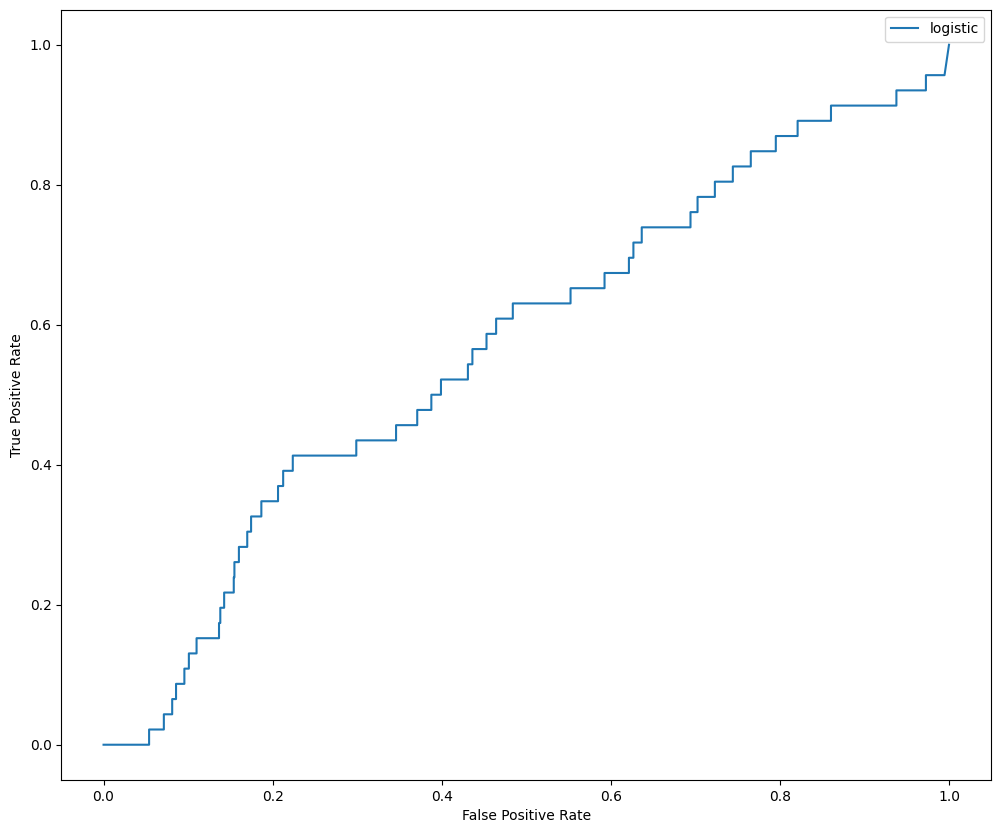

In [ ]:
# Plot the ROC curves
plt.figure(figsize=(12, 10))
plt.plot(logistic_fpr, logistic_tpr, label="logistic")
plt.legend()
plt.ylabel("True Positive Rate")
plt.xlabel("False Positive Rate")
plt.show()

In [ ]:
from sklearn.metrics import auc

# Get AUC
logistic_auc = auc(logistic_fpr, logistic_tpr)

# Print results
pd.DataFrame({"Model":['Logisitc Regression'], "AUC":[logistic_auc]})

,Model,AUC
0,Logisitc Regression,0.570199


In [ ]:
test_confusion_matrix=np.copy(confusion_matrix(y_test, logistic_preds))

In [ ]:
print("Recall=TP/(TP+FN)= ",test_confusion_matrix[1,1]/(test_confusion_matrix[1,1]+test_confusion_matrix[1,0]))

Recall=TP/(TP+FN)=  0.0


In [ ]:
#Investor perspective: Highly aware if the company would go bankrupt
#Set the prediction threshold to be 0.15, if the probability of
#going bankrupt is larger than 15%, then it would be predictied as True.

In [ ]:
investor_prediction=np.copy(logistic_preds_prob)

In [ ]:
investor_predict_bankeuptcy=[]

In [ ]:
for i in range(np.shape(investor_prediction)[0]):
  if investor_prediction[i,1]<=0.15:
    investor_predict_bankeuptcy.append(0)
  else:
    investor_predict_bankeuptcy.append(1)

In [ ]:
print(investor_predict_bankeuptcy)

[0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 

In [ ]:
print(f'This is confusion matrix for decision tree in investor perspective: \n{confusion_matrix(y_test, investor_predict_bankeuptcy)}')

This is confusion matrix for decision tree in investor perspective: 
[[1150  168]
 [  39    7]]


In [ ]:
investor_confusion_matrix=np.copy(confusion_matrix(y_test, investor_predict_bankeuptcy))

In [ ]:
print("In investor perspective: Recall=TP/(TP+FN)= ",investor_confusion_matrix[1,1]/(investor_confusion_matrix[1,1]+investor_confusion_matrix[1,0]))

In investor perspective: Recall=TP/(TP+FN)=  0.15217391304347827


In [ ]:
#We set cost as getting FP is 1, while FN is 10
#FP means investors would falsely identify a non-bankrupt company as bankrupt
#FN means investors would falsely identify a bankrupt company as non-bankrupt
#The cost of FN should be much higher than FP.
#Higher the cost, the worse it is.

In [ ]:
print("Cost:",investor_confusion_matrix[0,1]+investor_confusion_matrix[1,0]*10)

Cost: 558


In [ ]:
cost=investor_confusion_matrix[0,1]+investor_confusion_matrix[1,0]*10

In [ ]:
#We set gain of TP is 5, while TN is 0.5
#TP means investors would correctly identify a bankrupt company as bankrupt
#TN means investors would correctly identify a non-bankrupt company as non-bankrupt
#The gain of TP should be higher than TN
#In investors perspective, FP and FN should be more aware
#The value of cost should be larger than the value of gain
#because even it is non-bankrupt, it does not mean investor
#would earn a lot in that company
#Higher the gain, the better it is.

In [ ]:
print("Gain:", investor_confusion_matrix[0,0]*0.1+investor_confusion_matrix[1,1]*5)

Gain: 150.0


In [ ]:
#Net cost is used to calculate the cost including the earning when we correctly identify
#Net cost=cost-gain
#Higher the net cost, the worse it is.

In [ ]:
gain=investor_confusion_matrix[0,0]*0.1+investor_confusion_matrix[1,1]*5

In [ ]:
print("Net cost:", cost-gain)

Net cost: 408.0
